<div align="center">

# <span style="color: #3498db;">CA2 - Genetic and Games Algorithm</span>

**<span style="color:rgb(247, 169, 0);">Amir Parsa Mobed</span> - <span style="color:rgb(143, 95, 195);">810100271</span>**

</div>

# <span style="color: #3498db;">Genetic Algorithm</span>

## Imports

In [84]:
from bisect import bisect_left
from dataclasses import dataclass
from itertools import accumulate
from random import randrange, random, uniform
from typing import Callable, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm import tqdm


In [158]:
class ImageAnalysis:
    def __init__(self, image: Image, rows: int, columns: int):
        self._image = image
        self._rows = rows
        self._columns = columns
        self._pieces = self._split_image()
        self._dissimilarity_matrix = self._calculate_dissimilarity_matrix()

    @property
    def pieces(self) -> dict:
        return self._pieces

    def get_dissimilarity(self, ids: tuple, orientation: str) -> float:
        return self._dissimilarity_matrix[ids][orientation]

    def _split_image(self) -> dict:
        width, height = self._image.size
        piece_width = width // self._columns
        piece_height = height // self._rows

        pieces = {}
        for i in range(self._rows):
            for j in range(self._columns):
                left = j * piece_width
                top = i * piece_height
                right = left + piece_width
                bottom = top + piece_height
                piece = self._image.crop((left, top, right, bottom))
                pieces[i * self._columns + j] = piece
        return pieces

    def _calculate_dissimilarity_matrix(self) -> dict:
        matrix = {}
        for i in range(self._rows * self._columns):
            for j in range(self._rows * self._columns):
                if i == j:
                    continue
                matrix[i, j] = {
                    "L-R": self._dissimilarity_measure(self._pieces[i], self._pieces[j], "L-R"),
                    "T-D": self._dissimilarity_measure(self._pieces[i], self._pieces[j], "T-D"),
                }
        return matrix

    def _dissimilarity_measure(self, piece1: Image, piece2: Image, orientation: str) -> float:
        "Calculates pixel-wise squared difference between touching edges."
        edge1 = edge2 = None
        arr1 = np.asarray(piece1, dtype=np.int32)
        arr2 = np.asarray(piece2, dtype=np.int32)

        if orientation == "L-R":
            edge1, edge2 = arr1[:, -1, :], arr2[:, 0, :]
        elif orientation == "T-D":
            edge1, edge2 = arr1[-1, :, :], arr2[0, :, :]
        else:
            raise ValueError(f"Unsupported orientation: {orientation}")

        diff = edge1 - edge2
        return float(np.sum(diff * diff))


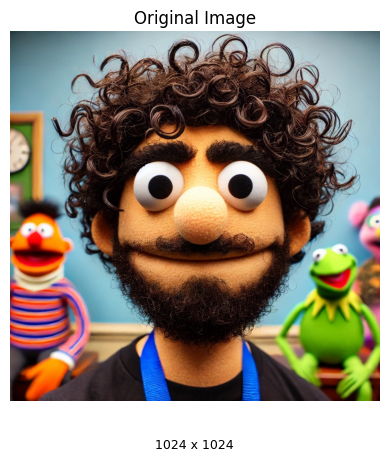

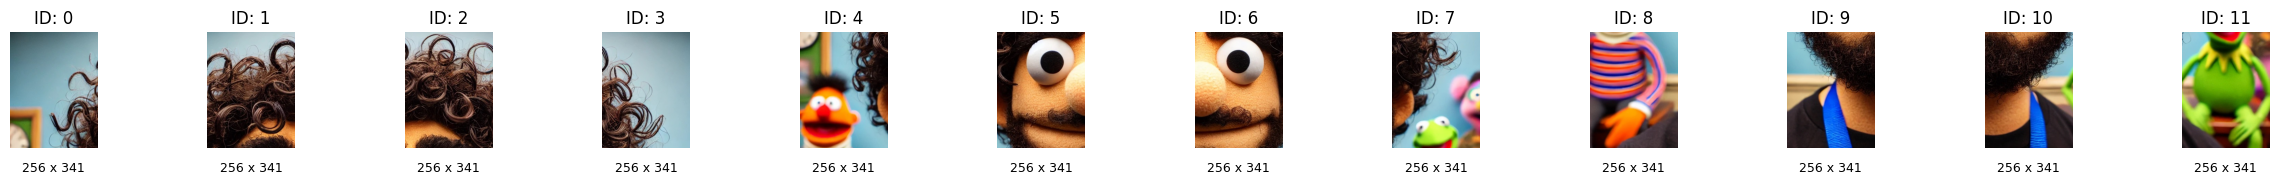

The ImageAnalysis class automatically divides the image into equal-sized pieces based on the specified number of rows and columns.


In [ ]:
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)

plt.title("Original Image")
plt.imshow(image)
plt.text(0.5, -0.1, f"{image.size[0]} x {image.size[1]}", transform=plt.gca().transAxes, ha="center", va="top", fontsize=9)
plt.axis("off")
plt.show()

imageAnalysis = ImageAnalysis(image, rows=3, columns=3)

pieces = imageAnalysis.pieces
ids = list(pieces.keys())
n = len(ids)

fig, axes = plt.subplots(1, n, figsize=(n * 2, 2))
if n == 1:
    axes = [axes]

for ax, pid in zip(axes, ids):
    img = pieces[pid]
    ax.imshow(img)
    ax.set_title(f"ID: {pid}")
    w, h = img.size
    ax.text(0.5, -0.12, f"{w} x {h}", transform=ax.transAxes, ha="center", va="top", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("The ImageAnalysis class automatically divides the image into equal-sized pieces based on the specified number of rows and columns.")


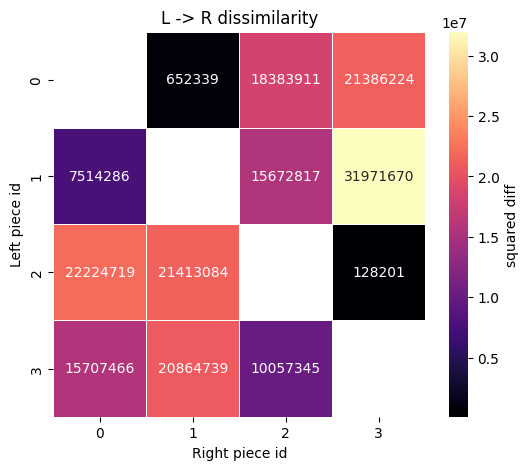

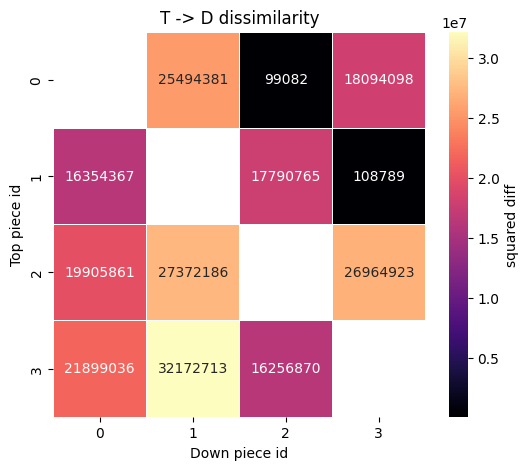

In [236]:
import pandas as pd
import seaborn as sns
from IPython.display import display

path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)

imageAnalysis = ImageAnalysis(image, rows=2, columns=2)

matrix = imageAnalysis._dissimilarity_matrix
ids = sorted(imageAnalysis.pieces.keys())
idx = {pid: i for i, pid in enumerate(ids)}
n = len(ids)

lr = np.full((n, n), np.nan)
td = np.full((n, n), np.nan)

for (i, j), scores in matrix.items():
    if i in idx and j in idx:
        lr[idx[i], idx[j]] = scores.get("L-R", np.nan)
        td[idx[i], idx[j]] = scores.get("T-D", np.nan)

df_lr = pd.DataFrame(lr, index=ids, columns=ids)
df_td = pd.DataFrame(td, index=ids, columns=ids)

plt.figure(figsize=(6, 5))
mask_lr = np.isnan(df_lr.values)
sns.heatmap(df_lr, mask=mask_lr, annot=True, fmt=".0f", cmap="magma", cbar_kws={'label': 'squared diff'}, linewidths=.5)
plt.title("L -> R dissimilarity")
plt.xlabel("Right piece id")
plt.ylabel("Left piece id")
plt.show()

plt.figure(figsize=(6, 5))
mask_td = np.isnan(df_td.values)
sns.heatmap(df_td, mask=mask_td, annot=True, fmt=".0f", cmap="magma", cbar_kws={'label': 'squared diff'}, linewidths=.5)
plt.title("T -> D dissimilarity")
plt.xlabel("Down piece id")
plt.ylabel("Top piece id")
plt.show()


## Image Analysis

### ImageAnalysis Class

The `ImageAnalysis` class is responsible for two main tasks:

1.  **Splitting the Image**: It takes the source image and splits it into a grid of smaller puzzle pieces.
2.  **Calculating Dissimilarity**: It computes a "dissimilarity matrix," which stores a score of how well any two pieces fit together. This is crucial for the genetic algorithm's fitness function.

You will need to implement the `_dissimilarity_measure` method, which is the core of the analysis. The rest of the class is provided for you.

### Task: Implement the `dissimilarity_measure` Method

The `dissimilarity_measure` method calculates how different two puzzle pieces are when placed next to each other. This is a key part of the fitness function, as it determines how well pieces fit together.

#### What You Need to Do:

-   **Implement the `_dissimilarity_measure` method** in the `ImageAnalysis` class.
-   The method should take two `PIL.Image` objects (`piece1`, `piece2`) and an `orientation` string (`"L-R"` for left-right or `"T-D"` for top-down).
-   It should return a single `float` value representing the dissimilarity.

#### Hints:

1.  **Convert Images to NumPy Arrays**: Use `np.asarray(piece)` to convert the `PIL.Image` objects into NumPy arrays. This makes it easier to perform mathematical operations on the pixel data.

2.  **Extract Edges**: Depending on the `orientation`, you need to extract the pixels from the touching edges of the two pieces.
    -   For `"L-R"` (Left-Right), you need the **right edge of `piece1`** and the **left edge of `piece2`**.
    -   For `"T-D"` (Top-Down), you need the **bottom edge of `piece1`** and the **top edge of `piece2`**.

3.  **Calculate Dissimilarity**: The dissimilarity can be calculated as the **sum of squared differences** between the pixel values of the two edges. The formula is:

    ```
    dissimilarity = sum((edge1 - edge2)^2)
    ```

    You can use `np.sum()` and basic arithmetic operations on the NumPy arrays to compute this value.

## Size Detector

In [161]:
class SizeDetector:
    def __init__(self, image: Image):
        self._image = image

    def detect(self) -> tuple:
        width, height = self._image.size
        aspect_ratio = width / height

        for i in range(1, int(width**0.5) + 1):
            if width % i == 0:
                j = width // i
                if abs(j / i - aspect_ratio) < 0.1:  # Heuristic for aspect ratio
                    return (i, j) if width > height else (j, i)
        return (1, width) # Fallback

In [210]:
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
detector = SizeDetector(image)
rows, columns = detector.detect()
print(f"Detected size: {rows} rows x {columns} columns")

Detected size: 32 rows x 32 columns


## Size Detector

### SizeDetector Class

The `SizeDetector` class automatically determines the size of the puzzle pieces from the input image. It works by analyzing the image's properties and looking for repeating patterns that suggest the dimensions of the pieces.

This class is provided to you and does not require any modifications. You can use it to get the piece size before starting the genetic algorithm.

## Individual

### Task: Implement the `Individual` Class

The `Individual` class represents a possible solution to the jigsaw puzzle. It stores the puzzle pieces and evaluates how well they fit together. You will need to implement several parts of this class to calculate the fitness and manage the puzzle pieces.

#### 1. Fitness Calculation (`fitness` property)

- **What You Need to Do**:
  - Implement the `fitness` property to calculate how well the pieces fit together.
  - The fitness value should be based on how the pieces align (i.e., their edges) both horizontally and vertically.
  - The fitness function should return an inverse fitness value based on the dissimilarities between adjacent pieces.

  **Hint**:
  - Use the `ImageAnalysis.get_dissimilarity(ids, orientation)` function to get the dissimilarity between adjacent pieces.
  - Calculate the dissimilarity between adjacent pieces both **horizontally** and **vertically** (Left-Right and Top-Down).

#### 2. Core Methods (`__init__`, `piece_size`, `piece_by_id`)

- **What You Need to Do**:
  - Implement the `__init__` method to initialize the puzzle with pieces and store the number of rows and columns.
  - Implement the `piece_size()` method to return the size of a single piece.
  - Implement the `piece_by_id()` method to retrieve a piece by its unique ID.

---

#### Parts You **Do Not Need to Implement**:

- **`edge` Method**:
  - This method checks the neighboring piece's ID based on orientation (top, right, bottom, left). It is useful for advanced puzzle assembly but is **not necessary** for this task. You can **skip** implementing this method.

- **`to_image` Method**:
  - This method reassembles the individual puzzle into a complete image. It is used for **visualization** of the solution and is **not required** for fitness evaluation. You can **skip** implementing this method.

In [163]:
class Individual:
    def __init__(self, pieces: dict, rows: int, columns: int, analysis: ImageAnalysis, initial_state: List[int] = None):
        self._analysis = analysis
        if self._analysis is None:
            raise ValueError("ImageAnalysis instance is required for computing fitness.")
        self._rows = rows
        self._columns = columns
        self._pieces = {}
        for piece_id, piece in pieces.items():
            try:
                setattr(piece, "id", getattr(piece, "id", piece_id))
            except Exception:
                pass
            self._pieces[piece_id] = piece

        piece_ids = list(self._pieces.keys())
        if initial_state is None:
            initial_state = list(np.random.permutation(piece_ids))
        self._chromosome = np.array(initial_state, dtype=int).reshape((rows, columns))
        self._fitness_cache = None

    @property
    def fitness(self) -> float:
        if self._fitness_cache is not None:
            return self._fitness_cache

        total_dissimilarity = 0.0
        if self._columns > 1:
            left_ids = self._chromosome[:, :-1].ravel()
            right_ids = self._chromosome[:, 1:].ravel()
            total_dissimilarity += sum(
                self._analysis.get_dissimilarity((int(l), int(r)), "L-R") for l, r in zip(left_ids, right_ids)
            )

        if self._rows > 1:
            top_ids = self._chromosome[:-1, :].ravel()
            bottom_ids = self._chromosome[1:, :].ravel()
            total_dissimilarity += sum(
                self._analysis.get_dissimilarity((int(t), int(b)), "T-D") for t, b in zip(top_ids, bottom_ids)
            )

        self._fitness_cache = 1.0 / (1.0 + total_dissimilarity)
        return self._fitness_cache

    def piece_size(self) -> tuple:
        first_piece = next(iter(self._pieces.values()))
        return first_piece.size

    def piece_by_id(self, piece_id: int) -> Image:
        return self._pieces[piece_id]

    def to_image(self) -> Image:
        piece_width, piece_height = self.piece_size()
        canvas_width = self._columns * piece_width
        canvas_height = self._rows * piece_height
        canvas = Image.new('RGB', (canvas_width, canvas_height))

        for i in range(self._rows):
            for j in range(self._columns):
                piece_id = self._chromosome[i, j]
                piece = self.piece_by_id(piece_id)
                canvas.paste(piece, (j * piece_width, i * piece_height))
        return canvas

    def __getitem__(self, key):
        return self._chromosome[key]

    def __repr__(self):
        return f"Individual(fitness={self.fitness})"


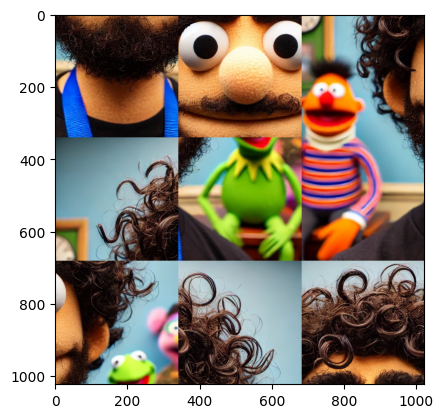

In [215]:
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
rows, columns = 3, 3

individual = Individual(
    pieces=ImageAnalysis(image, rows, columns).pieces,
    rows=rows,
    columns=columns,
    analysis=ImageAnalysis(image, rows, columns),
)
plt.imshow(individual.to_image())
plt.show()

## Selection

### Task: Implement the `roulette_selection` Function

The **roulette selection** process is part of the genetic algorithm and is used to select pairs of individuals from the population based on their **fitness**. The fitter individuals are more likely to be selected for reproduction, but all individuals still have a chance of being selected, even if their fitness is low.

---

#### **Hints**:

- You can use `random.uniform(0, total_sum)` to generate a random number between 0 and the total fitness sum.
- The `bisect_left` function helps find the position in the probability intervals where the random number fits.
- The **elites** are guaranteed to move to the next generation without crossover, so they should be excluded from the random selection process.

---

### Task: Implement Another Selection Method

Besides `roulette_selection`, there are other selection strategies. Implement one of the following:

1.  **Tournament Selection**:
    -   Randomly select a few individuals (a "tournament").
    -   The individual with the best fitness in the tournament is chosen as a parent.
    -   Repeat to select the second parent.

2.  **Rank Selection**:
    -   Rank the individuals by fitness.
    -   Selection probability is based on rank, not fitness value. This can prevent premature convergence.

In [165]:
def roulette_selection(population: List[Individual], elite_size: int) -> List[Tuple[Individual, Individual]]:
    "Roulette wheel selection based on fitness proportions."
    if not population:
        return []

    fitness_values = np.array([individual.fitness for individual in population], dtype=float)
    total_fitness = float(fitness_values.sum())
    if total_fitness == 0:
        probabilities = np.ones_like(fitness_values) / len(fitness_values)
    else:
        probabilities = fitness_values / total_fitness
    cumulative = np.cumsum(probabilities)

    def _spin() -> Individual:
        r = random()
        idx = bisect_left(cumulative, r)
        return population[min(idx, len(population) - 1)]

    pairs = []
    needed = max(len(population) - elite_size, 0)
    for _ in range(needed):
        pairs.append((_spin(), _spin()))
    return pairs

def tournament_selection(population: List[Individual], elite_size: int, tournament_size: int = 3) -> List[Tuple[Individual, Individual]]:
    "Tournament selection that keeps the fittest from random subsets."
    if not population:
        return []

    def _pick_one() -> Individual:
        sample_size = min(tournament_size, len(population))
        competitors = np.random.choice(population, size=sample_size, replace=False)
        return max(competitors, key=lambda ind: ind.fitness)

    pairs = []
    needed = max(len(population) - elite_size, 0)
    for _ in range(needed):
        pairs.append((_pick_one(), _pick_one()))
    return pairs


## Crossover

### Task: Implement the Crossover Logic

Crossover is where the "genetic" part of the algorithm happens. You'll create a new "child" individual by combining the traits of two "parent" individuals. The goal is to build a better-assembled puzzle by picking the best-fitting pieces from the parents.

This crossover strategy is complex. It starts with a random piece and then iteratively adds adjacent pieces based on a priority system.

#### Crossover Priority System:

1.  **Shared Pieces (Highest Priority)**: If two parents agree on a neighboring piece, that piece is chosen. This is a strong indicator of a correct fit.
2.  **Buddy Pieces (Medium Priority)**: A "buddy piece" is a pair of pieces that are each other's best match. If one of these is a neighbor, it's a good candidate.
3.  **Best Match (Lowest Priority)**: If neither of the above is found, choose the piece that has the lowest dissimilarity score (the best fit) from the remaining pieces.

---

#### Your Tasks:

1.  **Implement Piece Selection Methods**:
    -   `_get_shared_piece()`: Find pieces that are neighbors in **both** parents.
    -   `_get_buddy_piece()`: Find "buddy" pieces (mutual best friends).
    -   `_get_best_match_piece()`: Find the piece with the best dissimilarity score among the available pieces.

2.  **Implement the `Crossover` Class**:
    -   Use a `heapq` (min-heap) to manage candidate pieces based on the priority system.
    -   Implement the `run()` method to build the child's chromosome by selecting from the candidates.
    -   You can create different versions of the `add_piece_candidate` method to experiment with different strategies (e.g., one using only shared and best-match pieces, and another using all three).

3.  **Experiment and Compare**:
    -   After implementing the `Crossover` class, you can create variations of it. For example, one version might only use "shared" and "best match" pieces, while another could use all three priorities.
    -   Compare how these different crossover strategies affect the speed and quality of the solution. Does including "buddy pieces" help? Is it worth the extra computation?


In [166]:

import heapq

SHARED_PIECE_PRIORITY = -10
BUDDY_PIECE_PRIORITY = -1

def complementary_orientation(orientation):
    return {"T": "D", "R": "L", "D": "T", "L": "R"}.get(orientation)

class Crossover:
    def __init__(self, parent1: Individual, parent2: Individual, analysis: ImageAnalysis):
        self._parents = (parent1, parent2)
        self._analysis = analysis
        self._pieces_length = len(parent1._pieces)
        self._child_rows = parent1._rows
        self._child_columns = parent1._columns
        self._kernel = {}
        self._taken_positions = set()
        self._candidate_pieces = []
        self._min_row, self._max_row, self._min_column, self._max_column = 0, 0, 0, 0
        self._parent_positions = [self._index_parent(parent) for parent in self._parents]

    def run(self):
        self._initialize_kernel()
        while not self._is_kernel_full():
            while self._candidate_pieces and (
                self._candidate_pieces[0][1][0] in self._taken_positions
                or not self._is_valid_piece(self._candidate_pieces[0][1][1])
            ):
                heapq.heappop(self._candidate_pieces)

            if not self._candidate_pieces:
                if self._fallback_piece() is None:
                    break
                continue

            _, (position, piece_id), _ = heapq.heappop(self._candidate_pieces)
            if position in self._taken_positions or not self._is_valid_piece(piece_id):
                continue
            self._put_piece_to_kernel(piece_id, position)
        return self.child()

    def child(self) -> Individual:
        pieces = [None] * self._pieces_length
        for piece_id, (row, column) in self._kernel.items():
            index = (row - self._min_row) * self._child_columns + (column - self._min_column)
            pieces[index] = self._parents[0].piece_by_id(piece_id)

        used_piece_ids = {p.id for p in pieces if p is not None}
        all_pieces = {p.id: p for p in self._parents[0]._pieces.values()}
        unused_pieces = [all_pieces[pid] for pid in all_pieces if pid not in used_piece_ids]

        for i in range(self._pieces_length):
            if pieces[i] is None:
                pieces[i] = unused_pieces.pop()

        arrangement = [p.id for p in pieces]
        return Individual(dict(zip(arrangement, pieces)), self._child_rows, self._child_columns, self._analysis, arrangement)

    def _initialize_kernel(self):
        root_piece_id = list(self._parents[0]._pieces.keys())[randrange(self._pieces_length)]
        self._put_piece_to_kernel(root_piece_id, (0, 0))

    def _put_piece_to_kernel(self, piece_id: int, position: tuple):
        self._kernel[piece_id] = position
        self._taken_positions.add(position)
        self._update_candidate_pieces(piece_id, position)

    def _update_candidate_pieces(self, piece_id: int, position: tuple):
        for orientation, pos in self._available_boundaries(position):
            self.add_piece_candidate(piece_id, orientation, pos)

    def add_piece_candidate(self, piece_id: int, orientation: str, position: tuple):
        if position in self._taken_positions:
            return

        shared_piece = self._get_shared_piece(piece_id, orientation)
        if self._is_valid_piece(shared_piece):
            self._add_candidate_to_heap(SHARED_PIECE_PRIORITY, shared_piece, position, (piece_id, orientation))

        buddy_piece = self._get_buddy_piece(piece_id, orientation)
        if self._is_valid_piece(buddy_piece):
            self._add_candidate_to_heap(BUDDY_PIECE_PRIORITY, buddy_piece, position, (piece_id, orientation))

        best_piece, score = self._get_best_match_piece(piece_id, orientation)
        if self._is_valid_piece(best_piece) and score is not None:
            self._add_candidate_to_heap(score, best_piece, position, (piece_id, orientation))

    def _get_shared_piece(self, piece_id: int, orientation: str) -> int:
        neighbor0 = self._neighbor_in_parent(0, piece_id, orientation)
        neighbor1 = self._neighbor_in_parent(1, piece_id, orientation)
        if neighbor0 is not None and neighbor0 == neighbor1 and self._is_valid_piece(neighbor0):
            return neighbor0
        return None

    def _get_buddy_piece(self, piece_id: int, orientation: str) -> int:
        best_piece, _ = self._get_best_match_piece(piece_id, orientation)
        if not self._is_valid_piece(best_piece):
            return None
        reverse_orientation = complementary_orientation(orientation)
        partner, _ = self._get_best_match_piece(best_piece, reverse_orientation, include_piece_id=piece_id)
        if partner == piece_id:
            return best_piece
        return None

    def _get_best_match_piece(self, piece_id: int, orientation: str, include_piece_id: int = None) -> tuple:
        available_ids = [pid for pid in self._analysis.pieces.keys() if self._is_valid_piece(pid)]
        if include_piece_id is not None and include_piece_id not in available_ids:
            available_ids.append(include_piece_id)

        best_piece, best_score = None, None
        for candidate_id in available_ids:
            # Never compare a piece with itself; the dissimilarity matrix lacks (i, i).
            if candidate_id == piece_id:
                continue
            score = self._edge_score(piece_id, candidate_id, orientation)
            if best_score is None or score < best_score:
                best_piece, best_score = candidate_id, score
        return best_piece, best_score

    def _add_candidate_to_heap(self, priority: int, piece_id: int, position: tuple, relative_piece: tuple):
        heapq.heappush(self._candidate_pieces, (priority, (position, piece_id), relative_piece))

    def _edge_score(self, anchor_id: int, candidate_id: int, orientation: str) -> float:
        if orientation == "R":
            ids, key = (anchor_id, candidate_id), "L-R"
        elif orientation == "L":
            ids, key = (candidate_id, anchor_id), "L-R"
        elif orientation == "D":
            ids, key = (anchor_id, candidate_id), "T-D"
        elif orientation == "T":
            ids, key = (candidate_id, anchor_id), "T-D"
        else:
            raise ValueError(f"Unsupported orientation: {orientation}")
        return self._analysis.get_dissimilarity(ids, key)

    def _neighbor_in_parent(self, parent_idx: int, piece_id: int, orientation: str) -> int:
        pos = self._parent_positions[parent_idx].get(piece_id)
        if pos is None:
            return None
        row, col = pos
        offsets = {"T": (-1, 0), "R": (0, 1), "D": (1, 0), "L": (0, -1)}
        dr, dc = offsets[orientation]
        n_row, n_col = row + dr, col + dc
        if 0 <= n_row < self._child_rows and 0 <= n_col < self._child_columns:
            return int(self._parents[parent_idx]._chromosome[n_row, n_col])
        return None

    def _index_parent(self, parent: Individual) -> dict:
        mapping = {}
        for r in range(parent._rows):
            for c in range(parent._columns):
                mapping[int(parent._chromosome[r, c])] = (r, c)
        return mapping

    def _fallback_piece(self):
        available_positions = []
        for taken in list(self._taken_positions):
            available_positions.extend(self._available_boundaries(taken))
        if not available_positions:
            return None

        remaining_ids = [pid for pid in self._analysis.pieces.keys() if self._is_valid_piece(pid)]
        if not remaining_ids:
            return None

        orientation, pos = available_positions[0]
        self._put_piece_to_kernel(remaining_ids[0], pos)
        return remaining_ids[0]

    def _available_boundaries(self, row_and_column):
        (row, column) = row_and_column
        boundaries = []
        if not self._is_kernel_full():
            positions = {"T": (row - 1, column), "R": (row, column + 1), "D": (row + 1, column), "L": (row, column - 1)}
            for orientation, position in positions.items():
                if position not in self._taken_positions and self._is_in_range(position):
                    self._update_kernel_boundaries(position)
                    boundaries.append((orientation, position))
        return boundaries

    def _is_kernel_full(self):
        return len(self._kernel) == self._pieces_length

    def _is_in_range(self, pos):
        return self._is_row_in_range(pos[0]) and self._is_column_in_range(pos[1])

    def _is_row_in_range(self, row):
        return abs(min(self._min_row, row)) + abs(max(self._max_row, row)) < self._child_rows

    def _is_column_in_range(self, col):
        return abs(min(self._min_column, col)) + abs(max(self._max_column, col)) < self._child_columns

    def _update_kernel_boundaries(self, pos):
        self._min_row, self._max_row = min(self._min_row, pos[0]), max(self._max_row, pos[0])
        self._min_column, self._max_column = min(self._min_column, pos[1]), max(self._max_column, pos[1])

    def _is_valid_piece(self, piece_id):
        return piece_id is not None and piece_id not in self._kernel



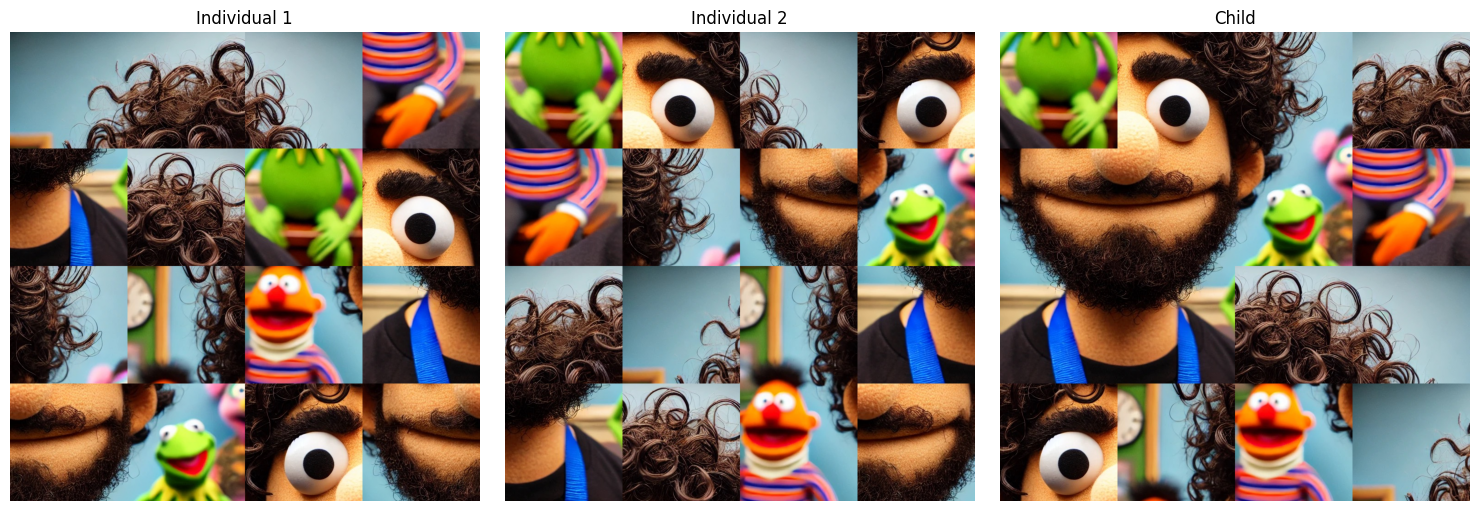

In [167]:
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
rows, columns = 4, 4

individual1 = Individual(
    pieces=ImageAnalysis(image, rows, columns).pieces,
    rows=rows,
    columns=columns,
    analysis=ImageAnalysis(image, rows, columns),
)
individual2 = Individual(
    pieces=ImageAnalysis(image, rows, columns).pieces,
    rows=rows,
    columns=columns,
    analysis=ImageAnalysis(image, rows, columns),
)

crossover = Crossover(individual1, individual2, ImageAnalysis(image, rows, columns))
child = crossover.run()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ind, title in zip(axes, [individual1, individual2, child], ["Individual 1", "Individual 2", "Child"]):
    ax.imshow(ind.to_image())
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

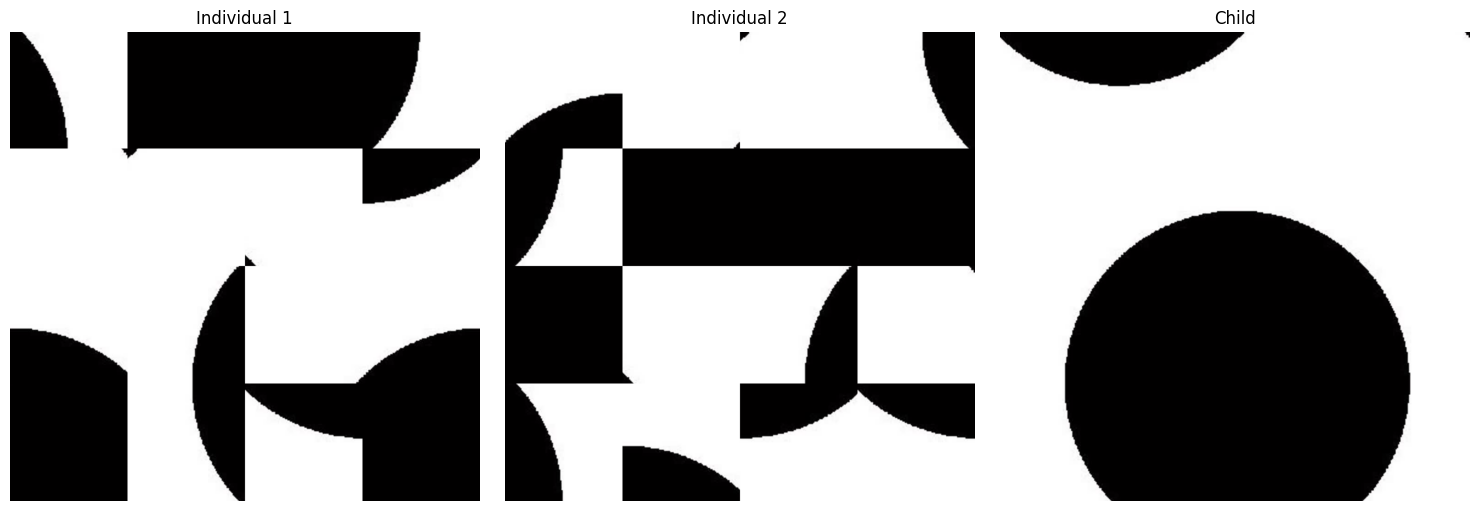

In [168]:
path_to_image = "./images/sample04.jpg"
image = Image.open(path_to_image)
rows, columns = 4, 4

individual1 = Individual(
    pieces=ImageAnalysis(image, rows, columns).pieces,
    rows=rows,
    columns=columns,
    analysis=ImageAnalysis(image, rows, columns),
)
individual2 = Individual(
    pieces=ImageAnalysis(image, rows, columns).pieces,
    rows=rows,
    columns=columns,
    analysis=ImageAnalysis(image, rows, columns),
)

crossover = Crossover(individual1, individual2, ImageAnalysis(image, rows, columns))
child = crossover.run()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ind, title in zip(axes, [individual1, individual2, child], ["Individual 1", "Individual 2", "Child"]):
    ax.imshow(ind.to_image())
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Mutation

In [137]:
def mutation(individual: Individual, mutation_rate: float = 0.01) -> Individual:
    "Swap random pieces based on the mutation rate."
    flat = individual._chromosome.reshape(-1).copy()
    length = len(flat)
    for idx in range(length):
        if random() < mutation_rate:
            swap_idx = randrange(length)
            flat[idx], flat[swap_idx] = flat[swap_idx], flat[idx]

    return Individual(
        individual._pieces,
        individual._rows,
        individual._columns,
        individual._analysis,
        flat.tolist(),
    )


## Genetic Algorithm

### Task: Implement the `GeneticAlgorithm` Class

This class simulates the process of evolution to solve the jigsaw puzzle using a **Genetic Algorithm**.

The genetic algorithm involves selection, crossover, and mutation processes to evolve better solutions over time.

---

In [ ]:
@dataclass
class GeneticAlgorithm:
    name: str
    image_path: str
    rows: int
    columns: int
    population_size: int
    elite_size: int
    mutation_rate: Callable[[int], float] | float
    selection_method: callable
    crossover_method: callable
    score_function: Callable | None
    max_generations: int = 200
    convergence_threshold: float = 1e-4
    patience: int = 10

    def __post_init__(self):
        self._analysis: Optional[ImageAnalysis] = None
        self._population: List[Individual] = []
        self._best_individual: Optional[Individual] = None
        self._best_fitness: float = -float("inf")
        self._generation: int = 0
        self._history = {"best": [], "best_so_far": [], "mean": [], "min": [], "var": []}
        self._best_individuals: List[Individual] = []
        self._mutation_rate_fn = self.mutation_rate if callable(self.mutation_rate) else lambda _: self.mutation_rate

    def init_gen(self):
        image = Image.open(self.image_path)
        self._analysis = ImageAnalysis(image, self.rows, self.columns)
        self._population = [
            Individual(self._analysis.pieces, self.rows, self.columns, self._analysis) for _ in range(self.population_size)
        ]
        self._best_individual = None
        self._best_fitness = -float("inf")
        self._generation = 0
        self._history = {"best": [], "best_so_far": [], "mean": [], "min": [], "var": []}
        self._best_individuals = []
        return self._population

    def _score(self, individual: Individual) -> float:
        return self.score_function(individual) if self.score_function else individual.fitness

    def _update_aggregates(self):
        if not self._population:
            return
        # assumes population sorted descending by score
        best_individual = self._population[0]
        best_current = float(self._score(best_individual))
        fitness_values = np.array([self._score(individual) for individual in self._population], dtype=float)
        mean_fitness = float(fitness_values.mean())
        min_fitness = float(fitness_values.min())
        var_fitness = float(fitness_values.var())

        if best_current > self._best_fitness:
            self._best_fitness = best_current
            self._best_individual = best_individual

        self._history["best"].append(best_current)
        self._history["best_so_far"].append(self._best_fitness)
        self._history["mean"].append(mean_fitness)
        self._history["min"].append(min_fitness)
        self._history["var"].append(var_fitness)
        self._best_individuals.append(best_individual)

    def go_next_gen(self):
        if not self._population:
            self.init_gen()

        self._population.sort(key=self._score, reverse=True)
        self._update_aggregates()

        rate = float(self._mutation_rate_fn(self._generation))
        next_generation = self._population[: self.elite_size]

        parent_pairs = self.selection_method(self._population, self.elite_size)
        for parent1, parent2 in parent_pairs:
            crossover_operator = self.crossover_method(parent1, parent2, self._analysis)
            child = crossover_operator.run() if hasattr(crossover_operator, "run") else crossover_operator
            next_generation.append(mutation(child, rate))
            if len(next_generation) >= self.population_size:
                break

        while len(next_generation) < self.population_size:
            next_generation.append(
                Individual(self._analysis.pieces, self.rows, self.columns, self._analysis)
            )

        self._population = next_generation
        self._generation += 1
        return self._best_individual

    def go_n_next_gen(self, n: int, improvement_threshold: Optional[float] = None) -> bool:
        threshold = self.convergence_threshold if improvement_threshold is None else improvement_threshold
        stagnation = 0
        for _ in range(n):
            prev_best = self._best_fitness
            self.go_next_gen()
            if self._best_fitness - prev_best < threshold:
                stagnation += 1
            else:
                stagnation = 0
            if stagnation >= self.patience:
                return True
        return False

    def run(self) -> Individual:
        if not self._population:
            self.init_gen()
        self.go_n_next_gen(self.max_generations, self.convergence_threshold)
        return self._best_individual

    def get_best_history(self) -> List[float]:
        return self._history["best"]

    def get_best_so_far_history(self) -> List[float]:
        return self._history["best_so_far"]

    def get_mean_history(self) -> List[float]:
        return self._history["mean"]

    def get_min_history(self) -> List[float]:
        return self._history["min"]

    def get_variance_history(self) -> List[float]:
        return self._history["var"]

    def get_best_individual(self) -> Optional[Individual]:
        return self._best_individual

    def get_best_individuals(self) -> List[Individual]:
        return self._best_individuals

    def get_generation(self) -> int:
        return self._generation


In [205]:
def plot_history(ga: GeneticAlgorithm, ax=None, label: str = None):
    """Single-run plots: mean, variance, and best curves side by side."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True) if ax is None else (ax.figure, [ax])
    gens = np.arange(len(ga.get_best_history()))

    axes[0].plot(gens, ga.get_mean_history(), color='C1')
    axes[0].set_title('Mean')
    axes[0].set_xlabel('Generation')
    axes[0].set_ylabel('Fitness')
    axes[0].grid(alpha=0.3)

    axes[1].plot(gens, ga.get_variance_history(), color='C2')
    axes[1].set_title('Variance')
    axes[1].set_xlabel('Generation')
    axes[1].grid(alpha=0.3)

    axes[2].plot(gens, ga.get_best_history(), color='C0', label=label or 'Best per gen')
    axes[2].plot(gens, ga.get_best_so_far_history(), color='C3', linestyle='--', label='Best so far')
    axes[2].set_title('Best')
    axes[2].set_xlabel('Generation')
    axes[2].grid(alpha=0.3)
    axes[2].legend()

    fig.tight_layout()
    return fig, axes

def plot_multiple_histories(algorithms: List[GeneticAlgorithm], labels: List[str] = None):
    """Overlay best/best-so-far curves for multiple runs; shows mean/variance of each in background."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True)
    for idx, ga in enumerate(algorithms):
        label = labels[idx] if labels else f"Run {idx + 1}"
        gens = np.arange(len(ga.get_best_history()))
        axes[0].plot(gens, ga.get_mean_history(), alpha=0.5, label=label)
        axes[1].plot(gens, ga.get_variance_history(), alpha=0.5, label=label)
        axes[2].plot(gens, ga.get_best_history(), alpha=0.6, label=f"{label} best")
        axes[2].plot(gens, ga.get_best_so_far_history(), linestyle='--', alpha=0.8, label=f"{label} best-so-far")

    axes[0].set_title('Mean')
    axes[0].set_xlabel('Generation')
    axes[0].set_ylabel('Fitness')
    axes[0].grid(alpha=0.3)

    axes[1].set_title('Variance')
    axes[1].set_xlabel('Generation')
    axes[1].grid(alpha=0.3)

    axes[2].set_title('Best')
    axes[2].set_xlabel('Generation')
    axes[2].grid(alpha=0.3)
    axes[2].legend()

    fig.tight_layout()
    return fig, axes

def plot_best_snapshots(ga: GeneticAlgorithm, count: int = 4):
    """Plot best-so-far individuals at equally spaced generations."""
    best_inds = ga.get_best_individuals()
    if not best_inds:
        raise ValueError("No best individuals recorded; run the GA first.")
    count = max(1, min(count, len(best_inds)))
    idxs = np.linspace(0, len(best_inds) - 1, num=count, dtype=int)
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 4))
    if count == 1:
        axes = [axes]
    for ax, idx in zip(axes, idxs):
        img = best_inds[idx].to_image()
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Gen {idx+1}")
    fig.tight_layout()
    return fig, axes

def plot_multiple_best_snapshots(gas: List[GeneticAlgorithm], count: int = 4):
    """Plot best-so-far individuals from multiple GA runs."""
    fig, axes = plt.subplots(len(gas), count, figsize=(4 * count, 4 * len(gas)))
    if len(gas) == 1:
        axes = [axes]
    for row_axs, ga in zip(axes, gas):
        best_inds = ga.get_best_individuals()
        if not best_inds:
            raise ValueError("No best individuals recorded; run the GA first.")
        cnt = max(1, min(count, len(best_inds)))
        idxs = np.linspace(0, len(best_inds) - 1, num=cnt, dtype=int)
        for ax, idx in zip(row_axs, idxs):
            img = best_inds[idx].to_image()
            ax.imshow(img)
            ax.axis('off')
            ax.set_title(f"Gen {idx+1}")
    fig.tight_layout()
    return fig, axes

def plot_first_n_gen_best_snapshots(ga: GeneticAlgorithm, count: int = 4):
    """Plot best-so-far individuals at the first n generations."""
    best_inds = ga.get_best_individuals()
    if not best_inds:
        raise ValueError("No best individuals recorded; run the GA first.")
    count = max(1, min(count, len(best_inds)))
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 4))
    if count == 1:
        axes = [axes]
    for ax, idx in zip(axes, range(count)):
        img = best_inds[idx].to_image()
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Gen {idx+1}")
    fig.tight_layout()
    return fig, axes

## Running the Algorithm

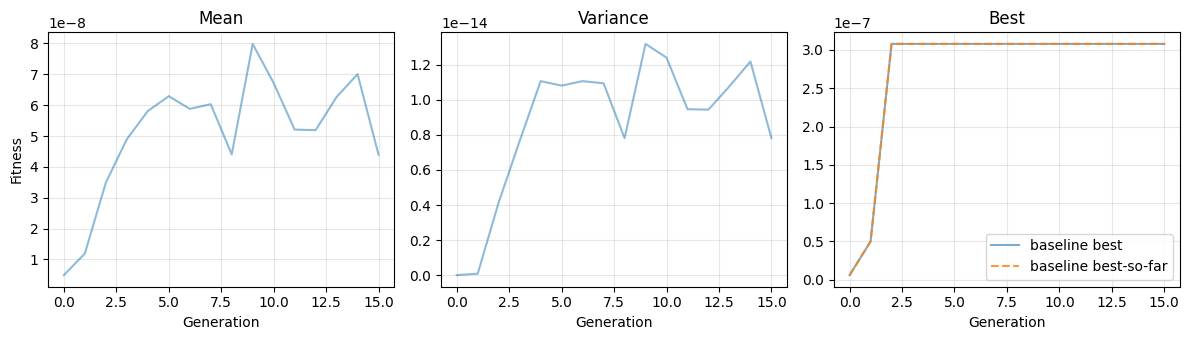

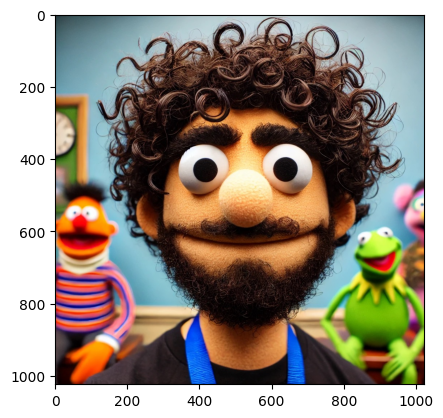

In [ ]:
def linear_decay_rate(initial: float, decay: float = 0.99, floor: float = 1e-4):
    "Returns a schedule where the mutation rate decays every generation."
    def schedule(gen: int) -> float:
        return max(floor, initial * (decay ** gen))
    return schedule
def run_hyperparameter_sweep(configs: List[dict], generations: int):
    runs = []
    for cfg in configs:
        ga = GeneticAlgorithm(**cfg)
        ga.init_gen()
        ga.go_n_next_gen(generations)
        runs.append(ga)
    return runs
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
rows, columns = 4, 4
example_configs = [
    {
        "name": "baseline",
        "image_path": path_to_image,
        "rows": rows,
        "columns": columns,
        "population_size": 40,
        "elite_size": 4,
        "mutation_rate": linear_decay_rate(0.05, decay=0.995, floor=0.001),
        "selection_method": tournament_selection,
        "crossover_method": lambda p1, p2, analysis: Crossover(p1, p2, analysis),
        "score_function": None,
        "max_generations": 150,
        "convergence_threshold": 1e-5,
        "patience": 15,
    },
]
runs = run_hyperparameter_sweep(example_configs, generations=100)
plot_multiple_histories(runs, labels=[cfg.get("name", f"run {i+1}") for i, cfg in enumerate(example_configs)])
best_solution = max(runs, key=lambda ga: ga.get_best_individual().fitness) if runs else None
plt.show()
if best_solution:
    plt.imshow(best_solution.get_best_individual().to_image())
    plt.show()


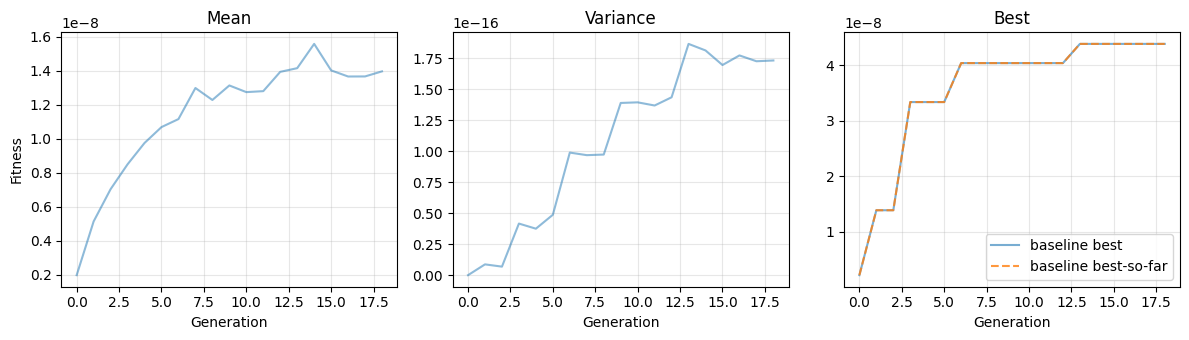

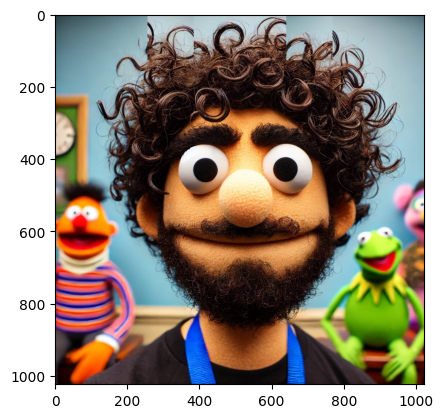

(<Figure size 2400x400 with 6 Axes>,
 array([<Axes: title={'center': 'Gen 1'}>,
        <Axes: title={'center': 'Gen 2'}>,
        <Axes: title={'center': 'Gen 3'}>,
        <Axes: title={'center': 'Gen 4'}>,
        <Axes: title={'center': 'Gen 5'}>,
        <Axes: title={'center': 'Gen 6'}>], dtype=object))

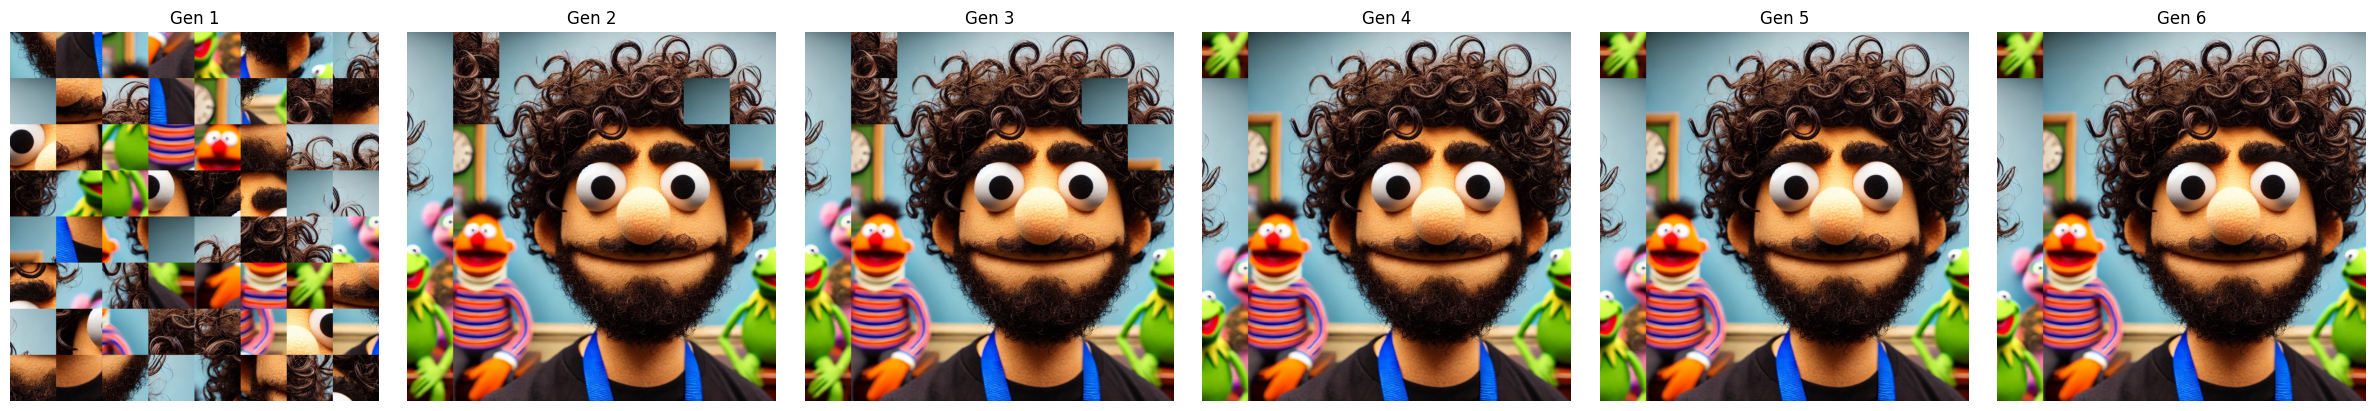

In [206]:
def linear_decay_rate(initial: float, decay: float = 0.99, floor: float = 1e-4):
    "Returns a schedule where the mutation rate decays every generation."
    def schedule(gen: int) -> float:
        return max(floor, initial * (decay ** gen))
    return schedule
def run_hyperparameter_sweep(configs: List[dict], generations: int):
    runs = []
    for cfg in configs:
        ga = GeneticAlgorithm(**cfg)
        ga.init_gen()
        ga.go_n_next_gen(generations)
        runs.append(ga)
    return runs
path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
rows, columns = 8, 8
example_configs = [
    {
        "name": "baseline",
        "image_path": path_to_image,
        "rows": rows,
        "columns": columns,
        "population_size": 20,
        "elite_size": 4,
        "mutation_rate": linear_decay_rate(0.05, decay=0.995, floor=0.001),
        "selection_method": tournament_selection,
        "crossover_method": lambda p1, p2, analysis: Crossover(p1, p2, analysis),
        "score_function": None,
        "max_generations": 150,
        "convergence_threshold": 1e-8,
        "patience": 15,
    },
]
runs = run_hyperparameter_sweep(example_configs, generations=100)
plot_multiple_histories(runs, labels=[cfg.get("name", f"run {i+1}") for i, cfg in enumerate(example_configs)])
best_solution = max(runs, key=lambda ga: ga.get_best_individual().fitness) if runs else None
plt.show()
if best_solution:
    plt.imshow(best_solution.get_best_individual().to_image())
    plt.show()

plot_first_n_gen_best_snapshots(runs[0], count=6)

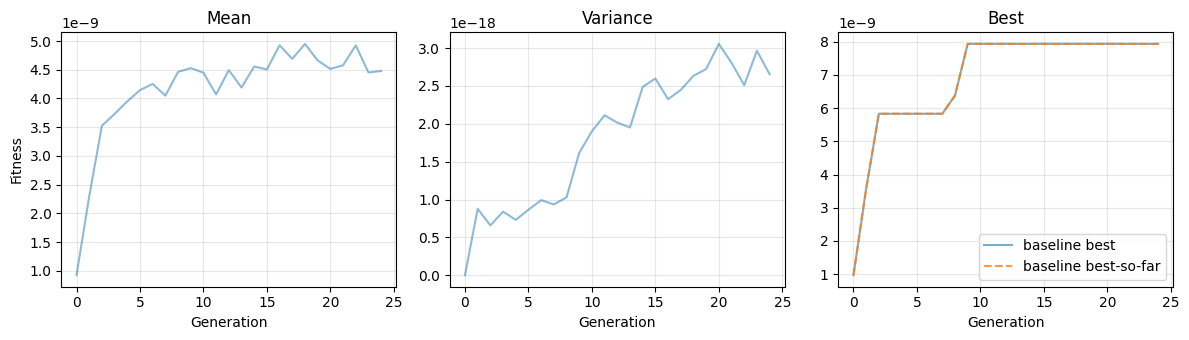

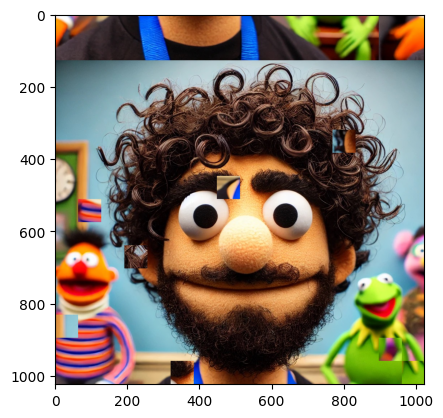

(<Figure size 2400x400 with 6 Axes>,
 array([<Axes: title={'center': 'Gen 1'}>,
        <Axes: title={'center': 'Gen 5'}>,
        <Axes: title={'center': 'Gen 10'}>,
        <Axes: title={'center': 'Gen 15'}>,
        <Axes: title={'center': 'Gen 20'}>,
        <Axes: title={'center': 'Gen 25'}>], dtype=object))

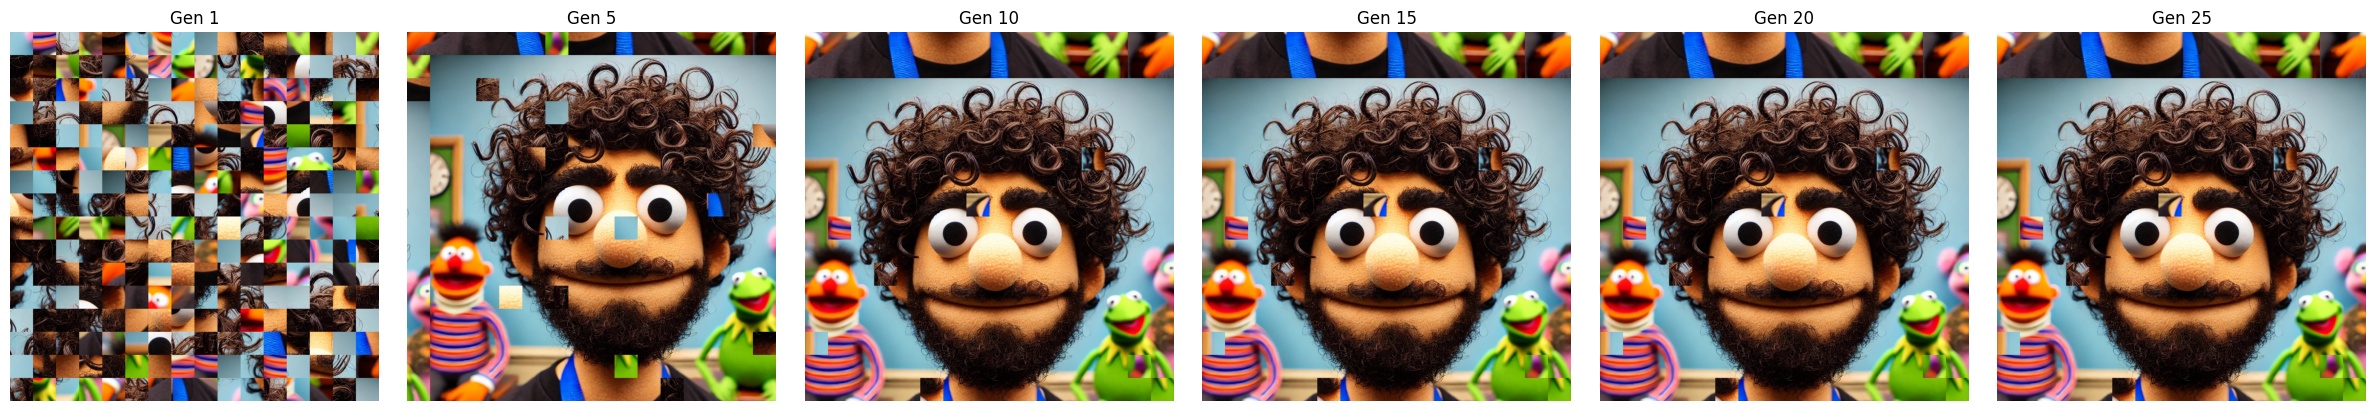

In [200]:
def run_hyperparameter_sweep(configs: List[dict], generations: int):
    runs = []
    for cfg in configs:
        ga = GeneticAlgorithm(**cfg)
        ga.init_gen()
        ga.go_n_next_gen(generations)
        runs.append(ga)
    return runs

path_to_image = "./images/me.jpg"
image = Image.open(path_to_image)
rows, columns = 16, 16
example_configs = [
    {
        "name": "baseline",
        "image_path": path_to_image,
        "rows": rows,
        "columns": columns,
        "population_size": 20,
        "elite_size": 4,
        "mutation_rate": 0.05,
        "selection_method": tournament_selection,
        "crossover_method": lambda p1, p2, analysis: Crossover(p1, p2, analysis),
        "score_function": None,
        "max_generations": 150,
        "convergence_threshold": 1e-10,
        "patience": 15,
    },
]
runs = run_hyperparameter_sweep(example_configs, generations=100)
plot_multiple_histories(runs, labels=[cfg.get("name", f"run {i+1}") for i, cfg in enumerate(example_configs)])
best_solution = max(runs, key=lambda ga: ga.get_best_individual().fitness) if runs else None
plt.show()
if best_solution:
    plt.imshow(best_solution.get_best_individual().to_image())
    plt.show()

plot_best_snapshots(runs[0], count=6)


<div style="color:rgb(235, 66, 32); font-weight: bold;">⚠️ Important Note:</div>  

Using **NumPy arrays** allows you to perform operations on vectors **more efficiently** and **faster**.

**Avoid using `for` loops** whenever possible, as vectorized operations in NumPy are **optimized for performance** and significantly reduce execution time.

# <span style="color: #3498db;">Dots and Boxes with Minimax Algorithm</span>

In this section, you will implement a **Minimax algorithm with Alpha-Beta pruning** to play the Dots and Boxes game. The game is already implemented, and you only need to focus on the AI agent that uses the Minimax algorithm to make intelligent decisions.

## Imports

In [2]:
import math
import numpy as np

from tkinter import *
from dataclasses import dataclass
from typing import List, Optional, Tuple

### **Dots and Boxes** is a classic two-player game where:
- Players take turns connecting adjacent dots with horizontal or vertical lines
- When a player completes the fourth side of a box, they score a point and get another turn
- The game ends when all lines are drawn, and the player with the most boxes wins

### Your Task

You will implement the **MinimaxAgent** class that uses:
1. **Minimax Algorithm**: A decision-making algorithm that explores the game tree to find the optimal move
2. **Alpha-Beta Pruning**: An optimization technique that reduces the number of nodes evaluated in the game tree
3. **Evaluation Function**: A heuristic to estimate the value of non-terminal game states

**Important**: You **MUST** implement Alpha-Beta pruning. This is a required optimization that significantly improves the algorithm's performance.

## GameState Class

The `GameState` class represents the current state of the game. It is **provided for you** and includes:
- `board_status`: Tracks how many edges each box has (values from 0-4)
- `row_status`: Tracks which horizontal edges are drawn
- `col_status`: Tracks which vertical edges are drawn
- `player1_turn`: Boolean indicating whose turn it is

### Key Methods (Already Implemented):
- `clone()`: Creates a copy of the game state
- `is_gameover()`: Checks if the game has ended
- `get_scores()`: Returns the current scores for both players
- `available_moves()`: Returns list of all valid moves
- `apply_move()`: Applies a move and returns whether a box was completed

In [3]:
@dataclass
class GameState:
    board_status: np.ndarray  # shape (n-1, n-1)
    row_status: np.ndarray    # shape (n, n-1)
    col_status: np.ndarray    # shape (n-1, n)
    player1_turn: bool

    def clone(self) -> "GameState":
        """Creates a deep copy of the current game state."""
        return GameState(
            board_status=self.board_status.copy(),
            row_status=self.row_status.copy(),
            col_status=self.col_status.copy(),
            player1_turn=self.player1_turn,
        )

    def get_dimensions(self) -> int:
        """Returns the number of dots (n) in the game grid."""
        return self.row_status.shape[0]

    def is_gameover(self) -> bool:
        """Checks if all edges have been drawn."""
        return (self.row_status == 1).all() and (self.col_status == 1).all()

    def get_scores(self) -> Tuple[int, int]:
        """Returns (player1_score, player2_score)."""
        p1 = int(np.count_nonzero(self.board_status == -4))
        p2 = int(np.count_nonzero(self.board_status == 4))
        return p1, p2

    def available_moves(self) -> List[Tuple[str, List[int]]]:
        """Returns a list of all valid moves as (move_type, [row, col])."""
        moves = []
        for c in range(self.row_status.shape[0]):
            for r in range(self.row_status.shape[1]):
                if self.row_status[c, r] == 0:
                    moves.append(("row", [r, c]))

        for c in range(self.col_status.shape[0]):
            for r in range(self.col_status.shape[1]):
                if self.col_status[c, r] == 0:
                    moves.append(("col", [r, c]))

        return moves

    def apply_move(self, move_type: str, logical_position: List[int]) -> bool:
        """
        Applies a move to the game state.
        Returns True if a box was completed, False otherwise.
        """
        r = logical_position[0]
        c = logical_position[1]
        val = 1
        player_modifier = -1 if self.player1_turn else 1

        scored = False
        n_dots = self.get_dimensions()

        if c < (n_dots - 1) and r < (n_dots - 1):
            cur = abs(self.board_status[c, r]) + val
            self.board_status[c, r] = cur * player_modifier
            if abs(self.board_status[c, r]) == 4:
                scored = True

        if move_type == "row":
            self.row_status[c, r] = 1
            if c >= 1:
                cur = abs(self.board_status[c - 1, r]) + val
                self.board_status[c - 1, r] = cur * player_modifier
                if abs(self.board_status[c - 1, r]) == 4:
                    scored = True

        elif move_type == "col":
            self.col_status[c, r] = 1
            if r >= 1:
                cur = abs(self.board_status[c, r - 1]) + val
                self.board_status[c, r - 1] = cur * player_modifier
                if abs(self.board_status[c, r - 1]) == 4:
                    scored = True

        return scored

## MinimaxAgent Class

You are required to implement the core Minimax algorithm with **Alpha-Beta pruning**.

## Task 1: Implement the Evaluation Function

The evaluation function estimates how good a game state is for the AI agent. A good evaluation function considers:
- **Score Difference**: The primary factor (your score vs opponent's score)
- **Strategic Position**: Boxes that are almost complete, control of the board, etc.

You can create your own evaluation function or use a simple one based on score difference.

## Task 2: Implement the Minimax Algorithm with Alpha-Beta Pruning

The minimax algorithm explores the game tree to find the optimal move. **You MUST implement Alpha-Beta pruning** to make it efficient.

### Key Concepts to Implement:
1. **Minimax**: 
   - Maximizing player tries to maximize the score
   - Minimizing player tries to minimize the score
   - Recursively evaluate game states to find the best move

2. **Alpha-Beta Pruning** (REQUIRED):
   - Alpha (α): The best value the maximizer can guarantee
   - Beta (β): The best value the minimizer can guarantee
   - If β ≤ α at any point, prune (skip) the remaining branches
   - This dramatically reduces the number of nodes evaluated

3. **Depth Limiting**:
   - Use `max_depth` to limit how far ahead the algorithm looks
   - When depth limit is reached, use the evaluation function

In [ ]:
class MinimaxAgent:
    def __init__(self, isPlayer1: bool = False):
        """
        Initialize the Minimax agent.
        Args:
            isPlayer1: True if this agent is Player 1, False if Player 2
        """
        self.isPlayer1 = isPlayer1

    @staticmethod
    def _evaluate(state: GameState, agentIsPlayer1: bool) -> float:
        """
        An evaluation function for non-terminal game states.
        This function should return a score indicating how favorable the state is
        for the agent. Higher scores mean better positions for the agent.
        """

        # TODO: Implement your evaluation function

        pass

    @staticmethod
    def _is_maximizing_turn(state: GameState, agentIsPlayer1: bool) -> bool:
        """
        TODO: Determine if the current turn is a maximizing turn for the agent.
        The agent maximizes when it's their turn, and minimizes when it's the opponent's turn.
        """

        # Implement this method based on the description provided

        pass

    @staticmethod
    def _order_moves(state: GameState, moves: List[Tuple[str, List[int]]]) -> List[Tuple[str, List[int]]]:
        """
        Helper method (PROVIDED): Orders moves for better alpha-beta pruning efficiency.
        Prioritizes moves that complete boxes, then safe moves, then risky moves.
        You can use this in your choose_move() and _minimax() methods.
        """
        completing_moves = []
        safe_moves = []
        risky_moves = []

        for move_type, pos in moves:
            test_state = state.clone()
            scored = test_state.apply_move(move_type, pos)

            if scored:
                completing_moves.append((move_type, pos))
            else:
                boxes_at_3 = int(np.count_nonzero(np.abs(test_state.board_status) == 3))
                if boxes_at_3 > int(np.count_nonzero(np.abs(state.board_status) == 3)):
                    risky_moves.append((move_type, pos))
                else:
                    safe_moves.append((move_type, pos))

        return completing_moves + safe_moves + risky_moves

    def choose_move(
        self, state: GameState, max_depth: Optional[int] = None
    ) -> Tuple[Optional[str], Optional[List[int]], float]:
        """
        Choose the best move using the Minimax algorithm with Alpha-Beta pruning.
        This is the main entry point that starts the minimax search.
        Remember: You MUST implement alpha-beta pruning in this method!

        Hint: Use self._order_moves(state, moves) to get optimally ordered moves for better pruning.
        """

        # TODO: Implement the move selection with alpha-beta pruning

        pass

    def _minimax(
        self,
        state: GameState,
        depth: int,
        max_depth: Optional[int],
        alpha: float,
        beta: float,
        maximizing: bool,
    ) -> float:
        """
        The Minimax algorithm with Alpha-Beta pruning.
        This is the core recursive function that explores the game tree.

        Important Notes:
        - You MUST implement the alpha-beta pruning checks (if beta <= alpha: break)
        - Remember that completing a box gives the player another turn
        - Don't forget to check whose turn it is for the next recursion
        - Use self._order_moves(state, moves) for better performance
        """

        # TODO: Implement the minimax algorithm with alpha-beta pruning

        pass

## Testing Your Implementation

Once you've implemented the Minimax agent, you can test it by playing against it or watching it play against itself.

### Evaluation Steps

To test if your implementation is working correctly:

1. **Test with small depth limits** (e.g., 2-3) first to ensure correctness
2. **Verify alpha-beta pruning** is working by adding counters to track how many nodes are evaluated
3. **Compare performance**: Without pruning vs with pruning
4. **Test different evaluation functions** and see which performs better

In [ ]:
# TODO: Test your MinimaxAgent implementation here
# You can create simple test cases to verify your algorithm works correctly

# Example: Create a simple game state and test the agent
# number_of_dots = 3  # Start with a small board
# initial_state = make_initial_state(number_of_dots, player1_starts=False)

# agent = MinimaxAgent(isPlayer1=False)
# move_type, position, value = agent.choose_move(initial_state, max_depth=2)
# print(f"Best move: {move_type} at {position} with value {value}")

In [ ]:
# Helper function for creating initial game states (useful for testing)
def make_initial_state(number_of_dots: int, player1_starts: bool = True) -> GameState:
    """
    Creates a new game state with an empty board.
    """
    board_status = np.zeros((number_of_dots - 1, number_of_dots - 1), dtype=int)
    row_status = np.zeros((number_of_dots, number_of_dots - 1), dtype=int)
    col_status = np.zeros((number_of_dots - 1, number_of_dots), dtype=int)
    return GameState(
        board_status=board_status, 
        row_status=row_status, 
        col_status=col_status, 
        player1_turn=player1_starts
    )

---

## Dots and Boxes Game Implementation

Below is the complete implementation of the Dots and Boxes game with a graphical user interface (GUI). This code is **provided for you** and integrates your MinimaxAgent to play against you or itself.

### How to Play:

1. **Run all the cells** in this section to start the game
2. The game will open in a new window
3. Click on the grid lines to draw edges
4. Try to complete boxes to score points
5. The AI (Player 2) will automatically make moves using your Minimax implementation
6. The game ends when all boxes are completed

### Game Configuration:

You can adjust these parameters:
- `number_of_dots`: Grid size (default is 6x6)
- `MAX_AI_DEPTH`: How many moves ahead the AI looks (default is 2)
- `ai_mode`: Set to `True` to play against AI, `False` for 2-player mode

In [5]:
# Game Configuration
MAX_AI_DEPTH = 2

size_of_board = 600
number_of_dots = 6
symbol_size = (size_of_board / 3 - size_of_board / 8) / 2
symbol_thickness = 50
dot_color = "#FFFFFF"
player1_color = '#0492CF'
player1_color_light = '#67B0CF'
player2_color = '#EE4035'
player2_color_light = '#EE7E77'
text_color = "#FFFFFF"
dot_width = 0.25*size_of_board/number_of_dots
edge_width = 0.1*size_of_board/number_of_dots
distance_between_dots = size_of_board / (number_of_dots)

In [ ]:
class Dots_and_Boxes():
    def __init__(self):
        self.window = Tk()
        self.window.title('Dots_and_Boxes')
        self.canvas = Canvas(self.window, width=size_of_board, height=size_of_board)
        self.canvas.pack()
        self.window.bind('<Button-1>', self.click)
        self.player1_starts = True
        self.ai_agent = MinimaxAgent(isPlayer1=False)
        self.ai_mode = True
        self.ai_max_depth = MAX_AI_DEPTH
        self.refresh_board()
        self.play_again()

    def play_again(self):
        self.refresh_board()
        self.board_status = np.zeros(shape=(number_of_dots - 1, number_of_dots - 1))
        self.row_status = np.zeros(shape=(number_of_dots, number_of_dots - 1))
        self.col_status = np.zeros(shape=(number_of_dots - 1, number_of_dots))
        self.pointsScored = False
        self.player1_starts = not self.player1_starts
        self.player1_turn = self.player1_starts
        self.reset_board = False
        self.turntext_handle = []
        self.already_marked_boxes = []
        self.ai_agent.isPlayer1 = False
        self.display_turn_text()
        self.ai_move_if_needed()

    def mainloop(self):
        self.window.mainloop()

    def is_grid_occupied(self, logical_position, type):
        r = logical_position[0]
        c = logical_position[1]
        occupied = True
        if type == 'row' and self.row_status[c][r] == 0:
            occupied = False
        if type == 'col' and self.col_status[c][r] == 0:
            occupied = False
        return occupied

    def convert_grid_to_logical_position(self, grid_position):
        grid_position = np.array(grid_position)
        position = (grid_position-distance_between_dots/4)//(distance_between_dots/2)

        type = False
        logical_position = []
        if position[1] % 2 == 0 and (position[0] - 1) % 2 == 0:
            r = int((position[0]-1)//2)
            c = int(position[1]//2)
            logical_position = [r, c]
            type = 'row'
        elif position[0] % 2 == 0 and (position[1] - 1) % 2 == 0:
            c = int((position[1] - 1) // 2)
            r = int(position[0] // 2)
            logical_position = [r, c]
            type = 'col'

        return logical_position, type

    def pointScored(self):
        self.pointsScored = True

    def mark_box(self):
        boxes = np.argwhere(self.board_status == -4)
        for box in boxes:
            if tuple(box) not in [tuple(b) for b in self.already_marked_boxes]:
                self.already_marked_boxes.append(list(box))
                color = player1_color_light
                self.shade_box(box, color)

        boxes = np.argwhere(self.board_status == 4)
        for box in boxes:
            if tuple(box) not in [tuple(b) for b in self.already_marked_boxes]:
                self.already_marked_boxes.append(list(box))
                color = player2_color_light
                self.shade_box(box, color)

    def get_game_state_from_gui(self):
        """Helper method to convert GUI state to GameState object."""
        return GameState(
            board_status=self.board_status.copy(),
            row_status=self.row_status.copy(),
            col_status=self.col_status.copy(),
            player1_turn=self.player1_turn
        )

    def is_ai_turn(self):
        return (not self.ai_agent.isPlayer1 and not self.player1_turn) or \
               (self.ai_agent.isPlayer1 and self.player1_turn)

    def ai_move_if_needed(self):
        if self.reset_board or not self.ai_mode or not self.is_ai_turn():
            return

        while True:
            if self.is_gameover():
                break

            state = GameState(
                board_status=self.board_status.copy(),
                row_status=self.row_status.copy(),
                col_status=self.col_status.copy(),
                player1_turn=self.player1_turn
            )

            move_type, pos, _ = self.ai_agent.choose_move(state, max_depth=self.ai_max_depth)
            if move_type is None:
                break

            self.update_board(move_type, pos)
            self.make_edge(move_type, pos)
            self.mark_box()
            self.refresh_board()

            if not self.pointsScored:
                self.player1_turn = not self.player1_turn

            self.pointsScored = False

            if self.is_gameover():
                self.display_gameover()
                break

            if not self.is_ai_turn():
                self.display_turn_text()
                break

    def update_board(self, type, logical_position):
        r = logical_position[0]
        c = logical_position[1]
        val = 1
        playerModifier = -1 if self.player1_turn else 1

        if c < (number_of_dots-1) and r < (number_of_dots-1):
            self.board_status[c][r] = (abs(self.board_status[c][r]) + val) * playerModifier
            if abs(self.board_status[c][r]) == 4:
                self.pointScored()

        if type == 'row':
            self.row_status[c][r] = 1
            if c >= 1:
                self.board_status[c-1][r] = (abs(self.board_status[c-1][r]) + val) * playerModifier
                if abs(self.board_status[c-1][r]) == 4:
                    self.pointScored()

        elif type == 'col':
            self.col_status[c][r] = 1
            if r >= 1:
                self.board_status[c][r-1] = (abs(self.board_status[c][r-1]) + val) * playerModifier
                if abs(self.board_status[c][r-1]) == 4:
                    self.pointScored()

    def is_gameover(self):
        return (self.row_status == 1).all() and (self.col_status == 1).all()

    def make_edge(self, type, logical_position):
        if type == 'row':
            start_x = distance_between_dots/2 + logical_position[0]*distance_between_dots
            end_x = start_x+distance_between_dots
            start_y = distance_between_dots/2 + logical_position[1]*distance_between_dots
            end_y = start_y
        elif type == 'col':
            start_y = distance_between_dots / 2 + logical_position[1] * distance_between_dots
            end_y = start_y + distance_between_dots
            start_x = distance_between_dots / 2 + logical_position[0] * distance_between_dots
            end_x = start_x

        if self.player1_turn:
            color = player1_color
        else:
            color = player2_color
        self.canvas.create_line(start_x, start_y, end_x, end_y, fill=color, width=edge_width)

    def display_gameover(self):
        player1_score = len(np.argwhere(self.board_status == -4))
        player2_score = len(np.argwhere(self.board_status == 4))

        if player1_score > player2_score:
            text = 'Winner: Player 1 '
            color = player1_color
        elif player2_score > player1_score:
            text = 'Winner: Player 2 '
            color = player2_color
        else:
            text = 'Its a tie'
            color = 'gray'

        self.canvas.delete("all")
        self.canvas.create_text(size_of_board / 2, size_of_board / 3, font="cmr 60 bold", fill=color, text=text)

        score_text = 'Scores \n'
        self.canvas.create_text(size_of_board / 2, 5 * size_of_board / 8, font="cmr 40 bold", fill=text_color,
                                text=score_text)

        score_text = 'Player 1 : ' + str(player1_score) + '\n'
        score_text += 'Player 2 : ' + str(player2_score) + '\n'
        self.canvas.create_text(size_of_board / 2, 3 * size_of_board / 4, font="cmr 30 bold", fill=text_color,
                                text=score_text)
        self.reset_board = True

        score_text = 'Click to play again \n'
        self.canvas.create_text(size_of_board / 2, 15 * size_of_board / 16, font="cmr 20 bold", fill="gray",
                                text=score_text)

    def refresh_board(self):
        for i in range(number_of_dots):
            x = i*distance_between_dots+distance_between_dots/2
            self.canvas.create_line(x, distance_between_dots/2, x,
                                    size_of_board-distance_between_dots/2,
                                    fill='gray', dash = (2, 2))
            self.canvas.create_line(distance_between_dots/2, x,
                                    size_of_board-distance_between_dots/2, x,
                                    fill='gray', dash=(2, 2))

        for i in range(number_of_dots):
            for j in range(number_of_dots):
                start_x = i*distance_between_dots+distance_between_dots/2
                end_x = j*distance_between_dots+distance_between_dots/2
                self.canvas.create_oval(start_x-dot_width/2, end_x-dot_width/2, start_x+dot_width/2,
                                        end_x+dot_width/2, fill=dot_color,
                                        outline=dot_color)

    def display_turn_text(self):
        text = 'Next turn: '
        if self.player1_turn:
            text += 'Player1'
            color = player1_color
        else:
            text += 'Player2'
            color = player2_color

        self.canvas.delete(self.turntext_handle)
        self.turntext_handle = self.canvas.create_text(size_of_board - 5*len(text),
                                                       size_of_board-distance_between_dots/8,
                                                       font="cmr 15 bold", text=text, fill=color)

    def shade_box(self, box, color):
        start_x = distance_between_dots / 2 + box[1] * distance_between_dots + edge_width/2
        start_y = distance_between_dots / 2 + box[0] * distance_between_dots + edge_width/2
        end_x = start_x + distance_between_dots - edge_width
        end_y = start_y + distance_between_dots - edge_width
        self.canvas.create_rectangle(start_x, start_y, end_x, end_y, fill=color, outline='')

    def click(self, event):
        if not self.reset_board:
            grid_position = [event.x, event.y]
            logical_positon, valid_input = self.convert_grid_to_logical_position(grid_position)
            if valid_input and not self.is_grid_occupied(logical_positon, valid_input):
                self.update_board(valid_input, logical_positon)
                self.make_edge(valid_input, logical_positon)
                self.mark_box()
                self.refresh_board()

                if not self.pointsScored:
                    self.player1_turn = not self.player1_turn

                self.pointsScored = False

                if self.is_gameover():
                    self.display_gameover()
                else:
                    self.display_turn_text()
                    if self.ai_mode:
                        self.ai_move_if_needed()
        else:
            self.canvas.delete("all")
            self.play_again()
            self.reset_board = False

## Run the Game

Execute the cell below to start playing! Make sure you have implemented the MinimaxAgent methods before running this.

In [ ]:
# Start the game
game_instance = Dots_and_Boxes()
game_instance.mainloop()